In [1]:
import numpy as np
import torch
import os
import glob
import matplotlib.pyplot as plt

In [207]:
import pandas as pd

# Load the config file into a DataFrame
config_file_path = 'bash_scripts/config/test.csv'
df = pd.read_csv(config_file_path)
# Strip leading and trailing spaces from column names
df.columns = df.columns.str.strip()
# Strip leading and trailing spaces from all entries
df = df.map(lambda x: x.strip().replace('\"','\'') if isinstance(x, str) else x)
# Iterate over each row in the DataFrame
for idx, row in df.iterrows():
    ckpt_path = f'ckpt/{row["dataset"]}_{row["usage"]}/{row["model"]}_{row["depth"]}/{row["lr"]}_{row["snr"]}_{row["snvr"]}'
    seeds = row["seed"].split(';')

    # check mean and std of test accuracy already computed
    if 'accuracy' in row and row['accuracy'] != '-' and row['accuracy'] != '*':
        n = int(row['accuracy'].split('(')[-1].split(')')[0])
        if n == len(seeds):
            continue

    best_accs = []
    for seed in seeds:
        seed_path = os.path.join(ckpt_path, seed)
        best_epoch_path = os.path.join(seed_path, 'best_epoch.pth')
        if not os.path.exists(best_epoch_path):
            continue
        best_epoch = torch.load(best_epoch_path)
        best_accs.append(best_epoch['test_acc'])        

    if not best_accs:
        continue
    mean_acc = np.mean(best_accs)
    std_acc = np.std(best_accs)
    df.at[idx, 'accuracy'] = f'{mean_acc:.2f} ± {std_acc:.2f} ({len(best_accs)})'

    
df.to_csv(config_file_path, index=False)
df

,dataset,usage,model,depth,lr,snr,snvr,seed,accuracy,remark
0,cifar100,1.0,resnet,18,0.10,0.0000,0.00,43;37;13;51;71,-,{}
1,cifar100,1.0,resnet,34,0.05,0.0000,0.00,43;37;13;51;71,-,{}
2,cifar100,1.0,vgg,16,0.10,0.0000,0.00,43;37;13;51;71,72.61 ± 0.28 (5),{}
3,cifar100,1.0,vgg,16,0.10,0.0050,0.00,43;37;13;51;71,72.52 ± 0.37 (5),{}
4,cifar100,1.0,vgg,16,0.05,0.0000,0.00,43;37;13;51;71,72.26 ± 0.55 (5),{}
5,cifar100,1.0,vgg_clf_4096,16,0.05,0.0000,0.00,43;37;13;51;71,71.95 ± 0.17 (5),{'linear_dim':4096}
6,cifar100,1.0,vgg_clf_1024,16,0.05,0.0000,0.00,43;37;13;51;71,71.91 ± 0.36 (5),{'linear_dim':1024}
7,cifar100,1.0,vgg_clf_512,16,0.05,0.0000,0.00,43;37;13;51;71,71.89 ± 0.09 (5),{'linear_dim':512}
8,cifar100,1.0,vgg_clf_256,16,0.05,0.0000,0.00,43;37;13;51;71,71.95 ± 0.32 (5),{'linear_dim':256}
9,cifar100,1.0,vgg_clf_128,16,0.05,0.0000,0.00,43;37;13;51;71,71.31 ± 0.21 (5),{'linear_dim':128}


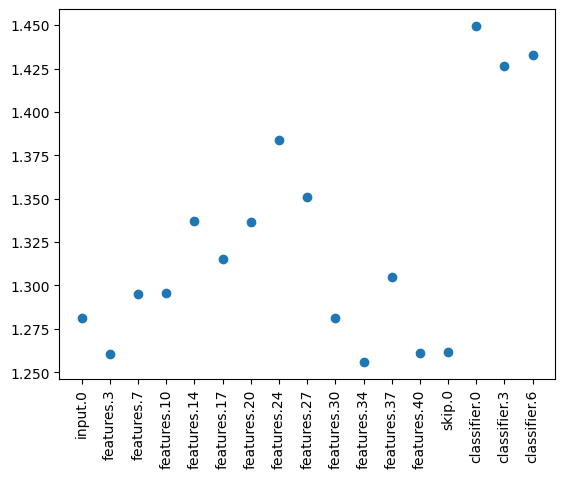

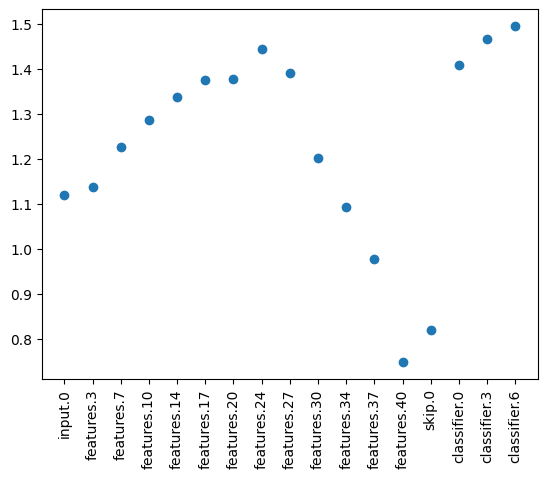

In [206]:
from sgdsnr import compute_weight


ckpts = [
    'ckpt/cifar100_1.0/vgg_clf_4096_skip_16/0.1_0.005_0.1/43/best_epoch.pth',
    'ckpt/cifar100_1.0/vgg_clf_4096_skip_16/0.1_0.005_0.01/43/best_epoch.pth',
]
for ckpt in ckpts:
    ckpt = torch.load(ckpt)
    x = []
    y = []
    for key in ckpt['model'].keys():
        if 'weight' not in key:
            continue
        w = ckpt['model'][key]
        if w.dim() > 1:
            sn, uv = compute_weight(w)
            x.append(key.replace('.weight',''))
            y.append(sn[0].item())

    plt.scatter(x,y)
    plt.xticks(rotation=90)
    plt.show()
    